In [1]:
import numpy as np
import pandas as pd
import spacy

In [2]:
#Read your train and test set
test = pd.read_csv('test_tickets.csv')
train = pd.read_csv('train_tickets.csv')

In [3]:
train

,Unnamed: 0,Description,Class
0,76,"In RGB mode stuck, lightsaber has become Hmm.....",Software issue
1,124,"Broken pc Hey, last Thursday my pc fell to the...",Purchase requisition
2,5,Ergonomic Chair Purchase We're running low on ...,Purchase requisition
3,116,Privacy glass on the windows It would be reall...,Privacy issue
4,163,Request for updated design software license Th...,Software issue
...,...,...,...
130,104,To many places in the building with cameras I ...,Privacy issue
131,129,Model deployment pipeline fails at Docker buil...,Software issue
132,183,IT Training Request Requesting training sessio...,Purchase requisition
133,174,Keyboard Not Responding The printer driver nee...,Software issue


In [4]:
train.drop("Unnamed: 0",axis=1 ,inplace=True)
test.drop("Unnamed: 0",axis=1 ,inplace=True)

C:\Users\Cathe\AppData\Local\Temp\ipykernel_36104\1600316279.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop("Unnamed: 0",axis=1 ,inplace=True)
C:\Users\Cathe\AppData\Local\Temp\ipykernel_36104\1600316279.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop("Unnamed: 0",axis=1 ,inplace=True)


In [ ]:
train

In [5]:
#Get the specific data as informed bellow
X_train = train['Description']
y_train = train['Class']

X_test = test['Description']
y_test = test['Class']

In [6]:
nlp = spacy.load('en_core_web_sm', disable = ['tagger','parser','ner'])

In [7]:
#Create a function to transform tickets in tokens
def transformToTokens(text):
    doc = nlp(text)
    tokens = [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop # we dont need the stopwords
    ]
    return " ".join(tokens)

In [8]:
from tqdm import tqdm
clean_train_tickets = [transformToTokens(t) for t in tqdm(X_train)]
clean_train_tickets
#Apply the previous function to the X_train
 

  0%|          | 0/135 [00:00<?, ?it/s]c:\Users\Cathe\AI_Frameworks\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 135/135 [00:00<00:00, 371.37it/s]


['rgb mode stuck lightsaber hmm problem installing latest security update broken lightsaber longer stable blade rgb mode displays red blue green flashing endlessly balance disco use battle impossible jedi tool toy fix',
 'broken pc hey thursday pc fell floor wanted know procedure require new sorry inconvenience thanks advance',
 'ergonomic chair purchase running low ergonomic chairs office order additional ergonomic chairs improve employee comfort',
 'privacy glass windows nice privacy glasses windows corporate building working street glass wall makes feel uncomfortable',
 'request updated design software license current license design application appears expired preventing file export collaboration kindly initiate renewal process assign active license',
 'cuda cpu use wo work ai training want use gpu check requirements met cuda',
 'replacement malfunctioning input device current keyboard intermittently fails register keystrokes significantly slowing report preparation appreciate repla

In [ ]:
clean_train_tickets

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))
train_data_features = vectorizer.fit_transform(clean_train_tickets)
#Create a CountVectorizer object 

In [10]:
vocab = vectorizer.get_feature_names_out()
print(vocab)

['ability' 'ability trained' 'ability use' ... 'yesterday'
 'yesterday prevents' 'yesterday stop']


In [11]:
train_data_features[0].toarray()

array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 3000))

In [12]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()

classifier.fit(train_data_features, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[45.,37.,53.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.1 ,-1.29,-0.93]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U20](3,)","['Privacy issue','Purchase requisition','Software issue']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 3000)","[[0.,0.,0.,...,1.,0.,1.], [1.,1.,0.,...,0.,0.,0.], [1.,0.,1.,...,1.,1.,0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 3000)","[[-8.42,-8.42,-8.42,...,-7.73,-8.42,-7.73], [-7.69,-7.69,-8.38,...,-8.38,-8.38,-8.38], [-7.78,-8.47,-7.78,...,-7.78,-7.78,-8.47]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3000


Preprocess and transform the test set!

In [13]:
clean_test_reviews = [transformToTokens(t) for t in tqdm(X_test)]
#perform the data processing in our test set 

  0%|          | 0/59 [00:00<?, ?it/s]c:\Users\Cathe\AI_Frameworks\.venv\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 59/59 [00:00<00:00, 427.36it/s]


In [ ]:
clean_test_reviews

In [14]:
test_data_features = vectorizer.transform(clean_test_reviews)

Check your score

In [20]:
#check the score
from sklearn.metrics import accuracy_score, classification_report
y_pred = classifier.predict(test_data_features)
test_accuracy_score = accuracy_score(y_test, y_pred)
test_classifier_score = classification_report(y_test, y_pred)
print('---test---')
print(test_accuracy_score)
print(test_classifier_score)


---test---
0.7796610169491526
                      precision    recall  f1-score   support

       Privacy issue       0.71      0.77      0.74        13
Purchase requisition       0.74      0.82      0.78        17
      Software issue       0.85      0.76      0.80        29

            accuracy                           0.78        59
           macro avg       0.77      0.78      0.77        59
        weighted avg       0.79      0.78      0.78        59



Look at your results and compare with your ground truth

In [16]:
#check the prediction
results = y_pred

In [17]:
y_test

0           Software issue
1            Privacy issue
2           Software issue
3           Software issue
4     Purchase requisition
5           Software issue
6           Software issue
7            Privacy issue
8           Software issue
9     Purchase requisition
10    Purchase requisition
11    Purchase requisition
12    Purchase requisition
13           Privacy issue
14    Purchase requisition
15           Privacy issue
16           Privacy issue
17           Privacy issue
18          Software issue
19    Purchase requisition
20          Software issue
21          Software issue
22          Software issue
23    Purchase requisition
24          Software issue
25          Software issue
26           Privacy issue
27    Purchase requisition
28           Privacy issue
29    Purchase requisition
30          Software issue
31    Purchase requisition
32    Purchase requisition
33          Software issue
34          Software issue
35          Software issue
36          Software issue
3

Plot a confusion matrix

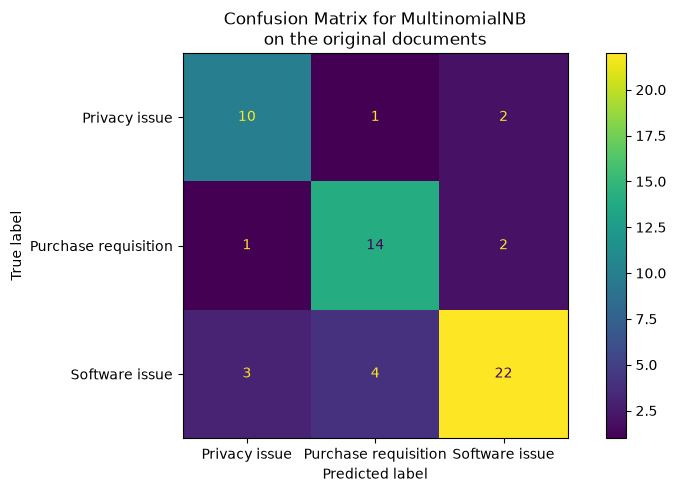

In [18]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

target_names = ['Privacy issue', 'Purchase requisition', 'Software issue']

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, results, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(f"Confusion Matrix for {classifier.__class__.__name__}\non the original documents")

**Not bad, right?**

Now is your time to play!


---> we use 5000 features, which can consist of unigrams (single words) or bigrams, when using the code below:

vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))


What you should do:
- Try to check another parameters, another combination and train your naive bayes model

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 1000,
                             ngram_range=(1,1))
train_data_features = vectorizer.fit_transform(clean_train_tickets)

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 3000,
                             ngram_range=(1,2))
train_data_features = vectorizer.fit_transform(clean_train_tickets)

analyzer{‘word’, ‘char’, ‘char_wb’} or callable, default=’word’
Whether the feature should be made of word n-gram or character n-grams. Option ‘char_wb’ creates character n-grams only from text inside word boundaries; n-grams at the edges of words are padded with space.
If a callable is passed it is used to extract the sequence of features out of the raw, unprocessed input.

max_featuresint, default=None
If not None, build a vocabulary that only consider the top max_features ordered by term frequency across the corpus. Otherwise, all features are used.
This parameter is ignored if vocabulary is not None.

--> array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 3312))

ngram_rangetuple (min_n, max_n), default=(1, 1)
The lower and upper boundary of the range of n-values for different word n-grams or char n-grams to be extracted. All values of n such such that min_n <= n <= max_n will be used. For example an ngram_range of (1, 1) means only unigrams, (1, 2) means unigrams and bigrams, and (2, 2) means only bigrams. Only applies if analyzer is not callable.

### Next

Apply other models:
- LogisticRegression
- BernoulliNB
- DecisionTreeClassifier



In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

models = {
    "MultinomialNB": MultinomialNB(),
    "BernoulliNB": BernoulliNB(),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(train_data_features, y_train)
    test_acc = model.score(test_data_features, y_test)
    print(f"{name:20s} {test_acc:.3f}")

MultinomialNB        0.780
BernoulliNB          0.610
LogisticRegression   0.729
DecisionTree         0.763


**Question:** Would you try a Neural Network in this data? Explain your thoughts.

No we need a lot more data for a NN to be good. NN has to have more samples to see the real connections, otherwise its going to overfit. 